# Q1. Camera

## (a)

### Task:
In Assignment 1, Q1, find the coordinates of the centre of the swinging load,
o1 (x, y, z) for all frames in training set rgb_train_val_swingingload.avi.
Use the M_int obtained in the Lab. Plot the 3D coordinates of swinging load for all frames.

### Approach:
1. Define the matrix from lab

2. Find the center pixel (u, v) of the swinging load in each frame and get the corresponding depth value.

3. Use the intrinsic matrix M_int to convert (u, v, depth) into 3D camera coordinates (X, Y, Z).

4. Save the 3D coordinates for all frames and plot the complete 3D trajectory.

In [1]:
import numpy as np

#1 Intrinsic matrix from lab
M_int = np.array([
    [1391.71768, 0.0, 979.101974],
    [0.0, 1388.53250, 540.246062],
    [0.0, 0.0, 1.0]
])
print(M_int)



[[1.39171768e+03 0.00000000e+00 9.79101974e+02]
 [0.00000000e+00 1.38853250e+03 5.40246062e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


In [3]:
#2 finding the RGB files, and depth filene.

from pathlib import Path
import cv2

rgb_folder = Path("Data/Train/rgb_frames")
depth_folder = Path("Data/Train/depth_raw")
rgb_files = sorted(rgb_folder.glob("*.png"))
depth_files = sorted(depth_folder.glob("*.npy"))

print("RGB frames:", len(rgb_files))
print("Depth frames:", len(depth_files))

RGB frames: 900
Depth frames: 900


In [4]:
#Picking up the yolo model for swinging load detection 

from ultralytics import YOLO
model = YOLO("YOLO_swinging_load.pt")

In [5]:
import json
#checks that the RGB frames, depth frames and depth-scale files are available,
#  and reads the depth scale needed to convert the raw depth values.

scale_folder = Path("Data/Train/depth_scale_json")
scale_files = sorted(scale_folder.glob("*.json"))

#print the number of RGB frames, depth frames, and depth scale files found, along with examples of each.
print("RGB frames:", len(rgb_files))
print("Depth frames:", len(depth_files))
print("Depth scale files:", len(scale_files))
print("Example RGB file:", rgb_files[0].name)
print("Example depth file:", depth_files[0].name)

#examines the first depth scale file, reads its content, and prints it out.
if scale_files:
    print("Example scale file:", scale_files[0].name)

    with open(scale_files[0], "r") as f:
        scale_data = json.load(f)

    print("Depth scale content:", scale_data)

RGB frames: 900
Depth frames: 900
Depth scale files: 1
Example RGB file: rgb_0000.png
Example depth file: depth_0000_raw.npy
Example scale file: depth_scale.json
Depth scale content: {'depth_scale': 0.0002500000118743628, 'timestamp': '20260918_152400'}


In [19]:
depth_values = []
centers = []

for rgb_path, depth_path in zip(rgb_files, depth_files):

    result = model.predict(str(rgb_path), verbose=False)[0]

    if result.boxes is None or len(result.boxes) == 0:
        continue

    i = int(result.boxes.conf.argmax())
    x1, y1, x2, y2 = result.boxes.xyxy[i].cpu().numpy()

    u = int((x1 + x2) / 2)
    v = int((y1 + y2) / 2)

    depth_raw = np.load(depth_path)

    # New fallback depth method
    if depth_raw[v, u] > 0:
        depth = depth_raw[v, u] * depth_scale

    else:
        x1i, y1i = max(0, int(x1)), max(0, int(y1))
        x2i = min(depth_raw.shape[1], int(x2))
        y2i = min(depth_raw.shape[0], int(y2))

        box_depth = depth_raw[y1i:y2i, x1i:x2i]

        valid_y, valid_x = np.where(box_depth > 0)

        if len(valid_x) > 0:
            valid_x = valid_x + x1i
            valid_y = valid_y + y1i

            distances = (valid_x - u)**2 + (valid_y - v)**2
            nearest = np.argmin(distances)

            depth = depth_raw[
                valid_y[nearest],
                valid_x[nearest]
            ] * depth_scale
        else:
            depth = np.nan

    centers.append((u, v))
    depth_values.append(depth)

In [20]:
valid_depths = np.sum(~np.isnan(depth_values))
nan_depths = np.sum(np.isnan(depth_values))

print("Valid depth values:", valid_depths)
print("Missing depth values:", nan_depths)

Valid depth values: 889
Missing depth values: 0


### Depth handling

We found that many of the center pixels had a depth value of 0, which means that there was no valid depth value at that exact pixel.

To solve this, we first used the depth value at the center pixel if it was available. If not, we used the closest valid depth value inside the YOLO bounding box.

This reduced the missing depth values from 336 to 0 for the 889 frames where the load was detected.

YOLO detected the swinging load in 889 of 900 frames.

In [38]:
# Remove large depth outliers using a local median

depth_array = np.array(depth_values, dtype=float)

window = 7
half_window = window // 2

depth_clean = depth_array.copy()

for i in range(len(depth_array)):
    start = max(0, i - half_window)
    end = min(len(depth_array), i + half_window + 1)

    local_median = np.median(depth_array[start:end])

    if abs(depth_array[i] - local_median) > 0.5:
        depth_clean[i] = np.nan

# Interpolate the removed outliers
valid = ~np.isnan(depth_clean)

depth_clean = np.interp(
    np.arange(len(depth_clean)),
    np.arange(len(depth_clean))[valid],
    depth_clean[valid]
)

print("Number of corrected depth values:",
      np.sum(np.abs(depth_array - depth_clean) > 0))

Number of corrected depth values: 70


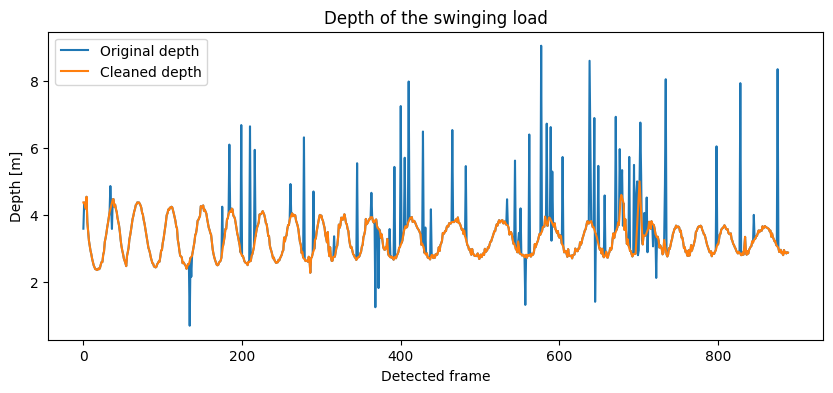

In [39]:
plt.figure(figsize=(10, 4))

plt.plot(depth_array, label="Original depth")
plt.plot(depth_clean, label="Cleaned depth")

plt.xlabel("Detected frame")
plt.ylabel("Depth [m]")
plt.title("Depth of the swinging load")
plt.legend()

plt.show()

In [47]:
# Step 3: Convert pixel coordinates and depth to 3D coordinates using the intrinsic matrix

fx = M_int[0, 0]
fy = M_int[1, 1]
cx = M_int[0, 2]
cy = M_int[1, 2]

o1 = []

for (u, v), depth in zip(centers, depth_clean):
    

    Z = depth
    X = (u - cx) * Z / fx
    Y = (v - cy) * Z / fy

    o1.append([X, Y, Z])

o1 = np.array(o1)

print("Number of 3D coordinates:", len(o1))
print("First 3D coordinate [X, Y, Z]:", o1[0])

Number of 3D coordinates: 889
First 3D coordinate [X, Y, Z]: [    -1.8052     -1.0079      4.3838]


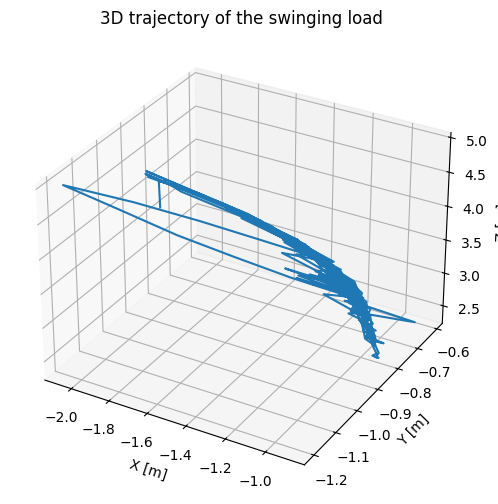

In [48]:
# Step 4: Plot the 3D trajectory

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(o1[:, 0], o1[:, 1], o1[:, 2])

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("3D trajectory of the swinging load")

plt.show()

### Depth filtering

The depth data contained several large spikes that did not match the continuous movement of the swinging load. Depth measurements can contain unreliable values, and depth filtering can therefore be used to remove unreliable measurements.

A local median was used to identify large depth outliers. Values that differed more than 0.5 m from the local median were treated as outliers and replaced by interpolation between neighbouring valid values.

The threshold was chosen based on the observed depth data to remove the clear spikes while keeping the general movement of the load.
YOLO detected the swinging load in 889 of 900 frames.


## (b)

### Task:
Say, the default intrinsic matrix of L515 is

\[
M_d =
\begin{bmatrix}
1342 & 0 & 325 \\
0 & 1342 & 235 \\
0 & 0 & 1
\end{bmatrix}
\]

Use this matrix to find the 3D coordinates of the center of the swinging load for all frames \((o_2)\) and plot them.

### Approach:
1. Define the default intrinsic matrix \(M_d\).

2. Use the same center pixel \((u, v)\) and depth values found in part (a).

3. Use \(M_d\) to convert \((u, v, depth)\) into 3D camera coordinates \((X, Y, Z)\).

4. Save the 3D coordinates as \(o_2\) and plot the complete 3D trajectory.

In [49]:
# Step 1: Define the default intrinsic matrix Md

Md = np.array([
    [1342.0, 0.0, 325.0],
    [0.0, 1342.0, 235.0],
    [0.0, 0.0, 1.0]
])

print(Md)

[[       1342           0         325]
 [          0        1342         235]
 [          0           0           1]]


In [50]:
# Step 2: Get the parameters from Md

fx_d = Md[0, 0]
fy_d = Md[1, 1]
cx_d = Md[0, 2]
cy_d = Md[1, 2]

print("fx:", fx_d)
print("fy:", fy_d)
print("cx:", cx_d)
print("cy:", cy_d)

fx: 1342.0
fy: 1342.0
cx: 325.0
cy: 235.0


In [51]:
# Step 3: Calculate 3D coordinates using Md

o2 = []

for (u, v), depth in zip(centers, depth_clean):

    Z = depth
    X = (u - cx_d) * Z / fx_d
    Y = (v - cy_d) * Z / fy_d

    o2.append([X, Y, Z])

o2 = np.array(o2)

print("Number of 3D coordinates:", len(o2))
print("First 3D coordinate [X, Y, Z]:", o2[0])

Number of 3D coordinates: 889
First 3D coordinate [X, Y, Z]: [    0.26459   -0.045732      4.3838]


In [52]:
print("o1 first point:", o1[0])
print("o2 first point:", o2[0])

o1 first point: [    -1.8052     -1.0079      4.3838]
o2 first point: [    0.26459   -0.045732      4.3838]


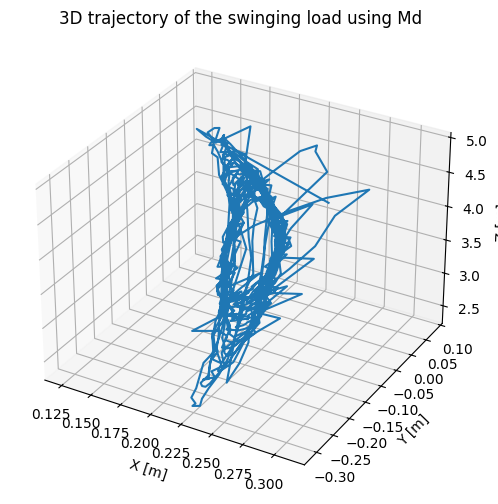

In [53]:
# Step 4: Plot the 3D trajectory using Md

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(o2[:, 0], o2[:, 1], o2[:, 2])

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("3D trajectory of the swinging load using Md")

plt.show()

The same detected center pixels and cleaned depth values from part (a) were used. The default intrinsic matrix \(M_d\) was then used to calculate the 3D coordinates o_2

## (c)

### Task:
Which intrinsic matrix, \(M_{int}\) or \(M_d\), is more accurate? Give reasons for the answer.

### Approach:
1. Compare the intrinsic parameters in \(M_{int}\) and \(M_d\).
2. Compare the principal point values with the image resolution.
3. Compare the focal length values with the camera specification.
4. Use the resulting 3D trajectories to support the conclusion.

In [54]:
# Compare intrinsic parameters

print("M_int:")
print("fx =", M_int[0, 0])
print("fy =", M_int[1, 1])
print("cx =", M_int[0, 2])
print("cy =", M_int[1, 2])

print("\nMd:")
print("fx =", Md[0, 0])
print("fy =", Md[1, 1])
print("cx =", Md[0, 2])
print("cy =", Md[1, 2])

M_int:
fx = 1391.71768
fy = 1388.5325
cx = 979.101974
cy = 540.246062

Md:
fx = 1342.0
fy = 1342.0
cx = 325.0
cy = 235.0


### Answer:

The default intrinsic matrix M_d seems to be more accurate for the images used in this assignment.

The images have a resolution of 640 × 480 pixels, so the image center is approximately (320, 240). The principal point in M_d is (325, 235), which is very close to the image center. In comparison, the principal point in \(M_{int}\) is approximately (979, 540), which does not match the image resolution used here.

The lecture notes also show that the focal length for the L515/OV2740 camera is approximately 1285 pixels. The focal length in M_d is 1342 pixels, while (M_{int} gives approximately 1390 pixels. Therefore, \(M_d\) is also closer to the expected focal length.

Based on both the principal point and the focal length, M_d appears to be more suitable for the 640 × 480 images used in this assignment.

## (d)

### Task:
From the data obtained in part (a) and (b), \(o_1\) and \(o_2\), implement a machine learning model that learns the function

\[
f_\theta(o_1) = o_2^*
\]

and evaluate the model using relevant KPIs.

### Approach:
1. Use \(o_1\) as input data and \(o_2\) as target data.
2. Split the data into training and test sets.
3. Train a regression model to learn the relationship between \(o_1\) and \(o_2\).
4. Predict \(o_2^*\) from the test data.
5. Evaluate the model using relevant regression KPIs.

In [58]:
# Step 1: Prepare input and target data

from sklearn.model_selection import train_test_split

X = o1
y = o2

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 711
Test samples: 178


In [59]:
# Step 2: Train a linear regression model

from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

model_lr.fit(X_train, y_train)

print("Model trained")

Model trained


In [60]:
# Step 3: Predict o2* from the test data

o2_star = model_lr.predict(X_test)

print("Number of predictions:", len(o2_star))
print("First predicted coordinate [X, Y, Z]:", o2_star[0])
print("First actual coordinate [X, Y, Z]:", y_test[0])

Number of predictions: 178
First predicted coordinate [X, Y, Z]: [    0.22369    -0.17463      2.6333]
First actual coordinate [X, Y, Z]: [    0.22369    -0.17463      2.6333]


In [61]:
# Step 4: Evaluate the model using RMSE

from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(y_test, o2_star))

print("RMSE:", rmse)

RMSE: 7.60695865875571e-16


In [62]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, o2_star)

print("R²:", r2)

R²: 1.0


### Results


The linear regression model predicted \(o_2\) very accurately from \(o_1\).

The RMSE was almost 0, meaning that there was almost no difference between the predicted and actual coordinates. The \(R^2\) value was 1.0, which shows that the model explains the relationship between \(o_1\) and \(o_2\) very well.

This makes sense since \(o_1\) and \(o_2\) are calculated from the same pixel and depth data, but with different intrinsic matrices.

## (e)

### Task:
Find the Euclidean error between:

1. \(o_1\) and \(o_2\)
2. \(o_1\) and \(o_2^*\)

and interpret the results.

### Approach:
1. Calculate the Euclidean distance between corresponding coordinates in \(o_1\) and \(o_2\).
2. Calculate the Euclidean distance between the test coordinates from \(o_1\) and the predicted coordinates \(o_2^*\).
3. Compare the errors and interpret the results.

In [63]:
# Step 1: Euclidean error between o1 and o2

error_o1_o2 = np.linalg.norm(o1 - o2, axis=1)

print("Mean Euclidean error o1 vs o2:", np.mean(error_o1_o2))
print("Minimum error:", np.min(error_o1_o2))
print("Maximum error:", np.max(error_o1_o2))

Mean Euclidean error o1 vs o2: 1.718149976340038
Minimum error: 1.1893629459818396
Maximum error: 2.6103445327317347


In [64]:
# Step 2: Euclidean error between o1 and o2*

error_o1_o2star = np.linalg.norm(X_test - o2_star, axis=1)

print("Mean Euclidean error o1 vs o2*:", np.mean(error_o1_o2star))
print("Minimum error:", np.min(error_o1_o2star))
print("Maximum error:", np.max(error_o1_o2star))

Mean Euclidean error o1 vs o2*: 1.713289468376552
Minimum error: 1.2926944485881782
Maximum error: 2.2808724171985504


### Results

The mean Euclidean error between \(o_1\) and \(o_2\) was about 1.72 m, while the mean error between \(o_1\) and \(o_2^*\) was about 1.71 m.

The errors are very similar because the linear regression model predicted \(o_2\) very accurately, so \(o_2^*\) is very close to \(o_2\).

The difference from \(o_1\) mainly comes from using different intrinsic matrices when calculating the 3D coordinates.

# Q2. Lidar

## (a)

### Task:
Use Ouster lidar data to find the center of the swinging load for all frames and plot the trajectory.

### Approach:
1. Load the lidar point cloud data for each frame.
2. Use clustering to separate the swinging load from the other points in the scene.
3. Find the centroid of the cluster representing the swinging load.
4. Save the centroid for each frame and plot the complete 3D trajectory.

# Q3. Camera-Lidar fusion

## (a)

### Task:
Get familiar with the KITTI data set. There are multiple cameras and Lidar used. It contains information about images taken from cameras, point cloud taken from lidar, and camera matrices. Illustrate your understanding in presentation.

### Approach:
1. Inspect the KITTI training data structure.
2. Understand what the camera images, LiDAR point clouds, calibration files, and labels contain.
3. Explain how the camera and LiDAR data are related through the calibration matrices.
4. Use examples from the training data to illustrate the dataset structure.

### KITTI data structure

For each frame, the KITTI training data has a camera image, lidar data, calibration data and labels.

For example, frame 000000 has:

- `image_2/000000.png` – camera image
- `velodyne/000000.bin` – lidar point cloud
- `calib/000000.txt` – calibration data
- `label_2/000000.txt` – ground truth label

The calibration data is used to connect the lidar data with the camera image, so the lidar points can be transformed into the camera coordinate system and shown in the image.

### Example frame
Frame 000000 is used to show how the camera image and lidar point cloud represent the same scene.


In [68]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

base_path = Path("/home/coder/.cache/kagglehub/datasets/garymk/kitti-3d-object-detection-dataset/versions/1/training")

image_path = base_path / "image_2" / "000000.png"

image = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)
plt.title("KITTI camera image - frame 000000")
plt.axis("off")
plt.show()


error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'
